In [1]:
import numpy as np
from numpy import cos, sin, exp, sqrt, log
import matplotlib.pyplot as plt
import pandas as pd
from dfit import Dfit
from scipy import linalg

## Question 2

In [2]:
df_1 = pd.read_excel('./decay1.xlsx')
df_2 = pd.read_excel('./decay2.xlsx')

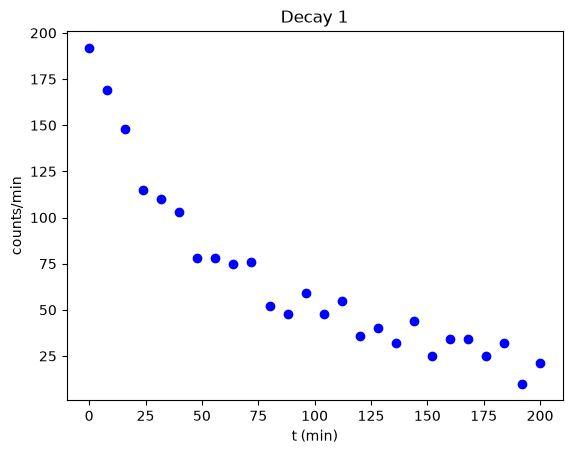

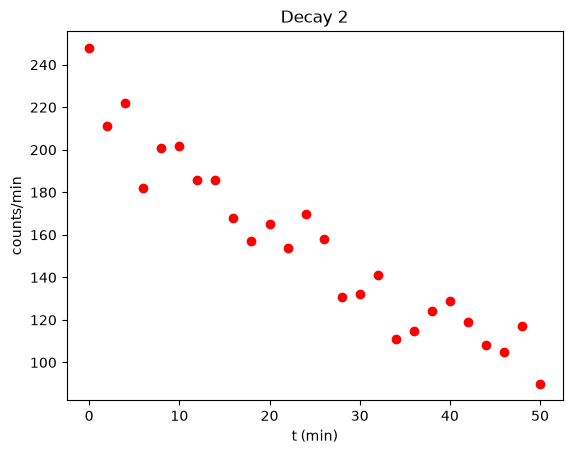

In [14]:
c0,c1 = list(df_1)
xs_1 = df_1[c0].to_numpy()
ys_1 = df_1[c1].to_numpy()
plt.scatter(xs_1,ys_1,c='b')
plt.xlabel(c0)
plt.ylabel(c1)
plt.title('Decay 1')
plt.show()

c0,c1 = list(df_2)
xs_2 = df_2[c0].to_numpy()
ys_2 = df_2[c1].to_numpy()
plt.scatter(xs_2,ys_2,c='r')
plt.xlabel(c0)
plt.ylabel(c1)
plt.title('Decay 2')
plt.show()

In [19]:
sigmas_1 = sqrt(ys_1)
sigmas_2 = sqrt(ys_2)

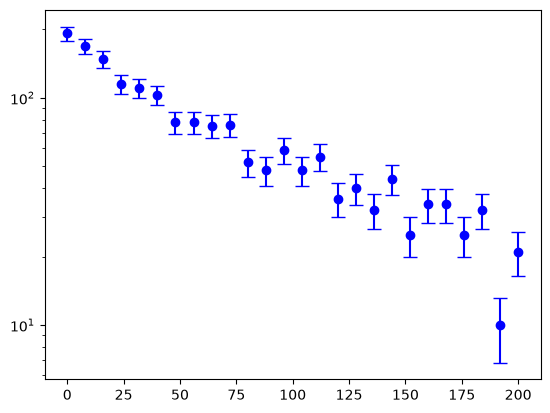

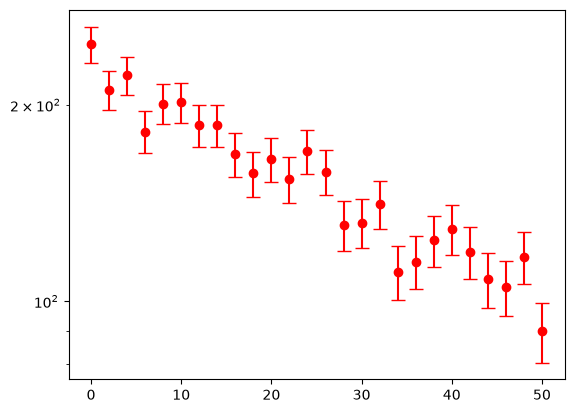

In [23]:
plt.errorbar(xs_1,ys_1,sigmas_1,fmt='bo',capsize=5)
plt.yscale('log')
plt.show()
plt.errorbar(xs_2,ys_2,sigmas_2,fmt='ro',capsize=5)
plt.yscale('log')
plt.show()

## Question 3

In [ ]:
def exp_fit(x, n_0, tau, bb):
    return n_0 * exp(-x/tau) + bb

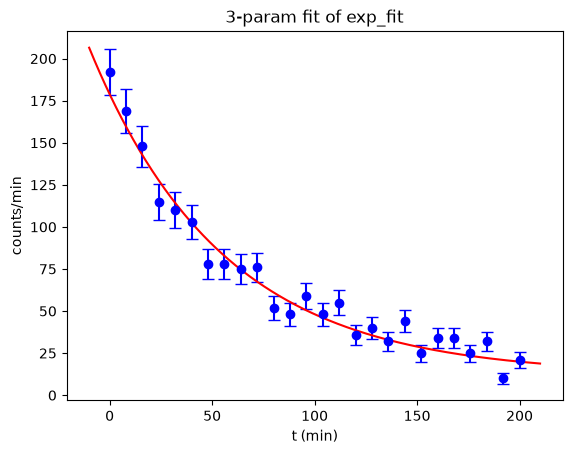

DATA SET: 26 points
FITTING FUNCTION: exp_fit, 3 variable parameters
Chi-squared = 38.64  Reduced chi-squared = 1.68
Parameters and 2-sigma parameter uncertainties:
       n_0 = 166.69      +/- 18.714     
       tau = 65.207      +/- 17.296     
        bb = 12.158      +/- 10.322     


In [48]:
guesses = [1, 1, 2]
fit_1 = Dfit(exp_fit,xs_1,ys_1,sigmas_1, p0s = guesses)
fit_1.plotfit(xlabel=c0,ylabel=c1)
fit_1.printfit()

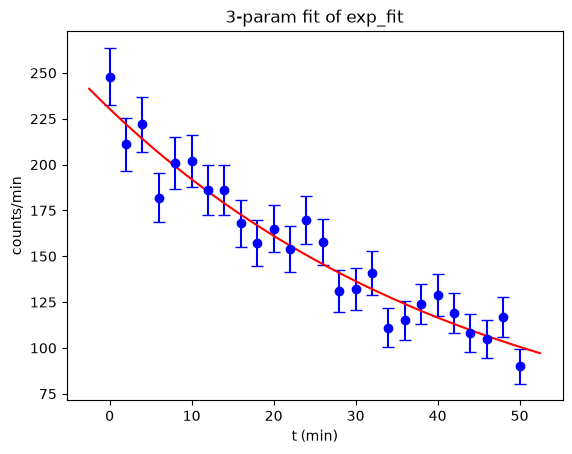

DATA SET: 26 points
FITTING FUNCTION: exp_fit, 3 variable parameters
Chi-squared = 19.41  Reduced chi-squared = 0.844
Parameters and 2-sigma parameter uncertainties:
       n_0 = 194.79      +/- 82.947     
       tau = 45.574      +/- 36.965     
        bb = 35.588      +/- 92.207     


In [49]:
guesses = [1, 1, 2]
fit_2 = Dfit(exp_fit,xs_2,ys_2,sigmas_2, p0s = guesses)
fit_2.plotfit(xlabel=c0,ylabel=c1)
fit_2.printfit()

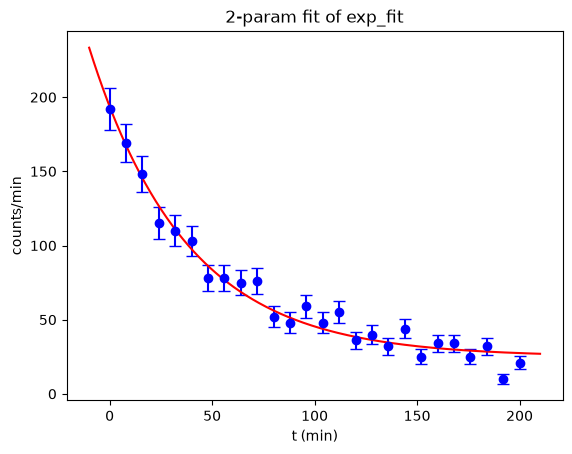

DATA SET: 26 points
FITTING FUNCTION: exp_fit, 2 variable parameters
Chi-squared = 53.81  Reduced chi-squared = 2.242
Parameters and 2-sigma parameter uncertainties:
       n_0 = 168.7       +/- 25.348     
       tau = 47.365      +/- 7.7293     
        bb = 25.0            (fixed)    


In [50]:
guesses = [1, 1, 25]
fit_1_fix = Dfit(exp_fit,xs_1,ys_1,sigmas_1, p0s = guesses, varies = [True, True, False])
fit_1_fix.plotfit(xlabel=c0,ylabel=c1)
fit_1_fix.printfit()

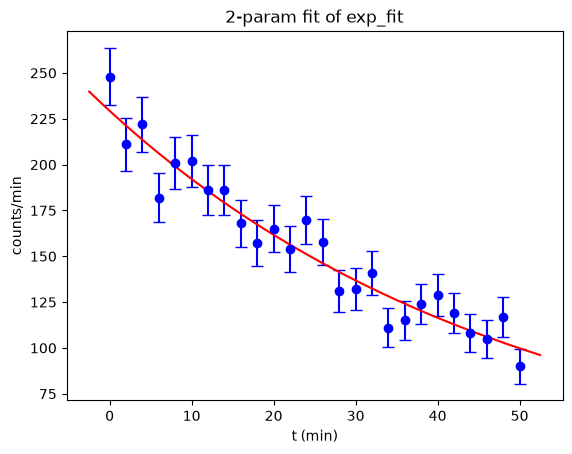

DATA SET: 26 points
FITTING FUNCTION: exp_fit, 2 variable parameters
Chi-squared = 19.45  Reduced chi-squared = 0.8103
Parameters and 2-sigma parameter uncertainties:
       n_0 = 204.29      +/- 11.788     
       tau = 49.782      +/- 5.8279     
        bb = 25.0            (fixed)    


In [51]:
guesses = [1, 1, 25]
fit_2_fix = Dfit(exp_fit,xs_2,ys_2,sigmas_2, p0s = guesses, varies = [True, True, False])
fit_2_fix.plotfit(xlabel=c0,ylabel=c1)
fit_2_fix.printfit()

## Question 4

In [53]:
u = np.array((2, 0))
v = np.array((1, 1))

print(f'u.v = {u @ v}')

u.v = 2


## Question 5

In [59]:
aa = np.array(((1, 3), (2, 4), (5, 6)))
bb = np.array(((2, 1, 4), (3, 2, 1)))
print(f'aa = \n{aa}, \nbb = \n{bb}')
print(f'matmul(aa, bb) = \n{np.matmul(aa, bb)}')
print(f'matmul(bb, aa) = \n{np.matmul(bb, aa)}')

aa = 
[[1 3]
 [2 4]
 [5 6]], 
bb = 
[[2 1 4]
 [3 2 1]]
matmul(aa, bb) = 
[[11  7  7]
 [16 10 12]
 [28 17 26]]
matmul(bb, aa) = 
[[24 34]
 [12 23]]


## Question 6

In [2]:
cc = np.array(((1, 3, 2),
               (2, 4, 1),
               (5, 6, 6)))
print(f'cc = \n{cc}')
print(f'cc^-1 = \n{np.linalg.inv(cc)}')
print(f'cc * cc^-1 = \n{np.matmul(cc, np.linalg.inv(cc))}')

cc = 
[[1 3 2]
 [2 4 1]
 [5 6 6]]
cc^-1 = 
[[-0.94736842  0.31578947  0.26315789]
 [ 0.36842105  0.21052632 -0.15789474]
 [ 0.42105263 -0.47368421  0.10526316]]
cc * cc^-1 = 
[[1.00000000e+00 0.00000000e+00 2.77555756e-17]
 [1.66533454e-16 1.00000000e+00 1.38777878e-17]
 [1.11022302e-16 5.55111512e-16 1.00000000e+00]]


## Question 7

In [ ]:
aa = np.array(((1, 4, 1),
                (4, -1, -1),
                (2, 1, 3)))
rhs = np.array((-4, 3, 7))

In [112]:
print(f'solution (via inv): {np.matmul(np.linalg.inv(aa), rhs)}')
print(f'solution (via solve): {np.linalg.solve(aa, rhs)}')

solution (via inv): [ 0.88461538 -1.80769231  2.34615385]
solution (via solve): [ 0.88461538 -1.80769231  2.34615385]


In [113]:
aa[2] @ np.linalg.solve(aa, rhs)

np.float64(7.0)

## Question 8

In [ ]:
theta = np.pi / 16
rr_theta = np.array(((cos(theta), -sin(theta)),
                     (sin(theta), cos(theta))))

print(f'R^T.R (should be I): \n{np.matmul(np.transpose(rr_theta), rr_theta)}')

R^T.R (should be I): 
[[ 1.00000000e+00 -2.72866517e-19]
 [-2.72866517e-19  1.00000000e+00]]


In [ ]:
r = np.array((1, 0))
theta = np.pi / 4
rr_theta = np.array(((cos(theta), -sin(theta)),
                     (sin(theta), cos(theta))))
print(f'r\': {np.matmul(rr_theta, r)}')

r': [-1.0000000e+00  1.2246468e-16]


In [81]:
theta = np.pi / 2
rr_theta = np.array(((cos(theta), -sin(theta)),
                     (sin(theta), cos(theta))))
print(f'r\': {np.matmul(rr_theta, r)}')

r': [6.123234e-17 1.000000e+00]


In [82]:
theta = 3 * np.pi / 2
rr_theta = np.array(((cos(theta), -sin(theta)),
                     (sin(theta), cos(theta))))
print(f'r\': {np.matmul(rr_theta, r)}')

r': [-1.8369702e-16 -1.0000000e+00]


# Question 9

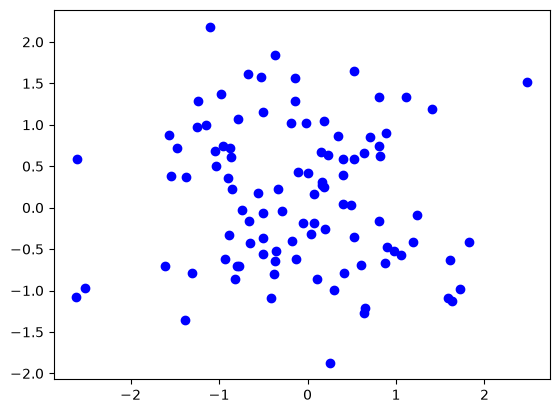

In [84]:
rng = np.random.default_rng() # get a random number generator
# use it to make some arrays of normally-distributed numbers.
x = rng.normal(size=100)
y = rng.normal(size=100)
plt.plot(x, y, 'bo')

In [99]:
theta = np.pi / 100
rr_theta = np.array(((cos(theta), -sin(theta)),
                     (sin(theta), cos(theta))))
xr = np.zeros(len(x))
yr = np.zeros(len(y))
for i in range(len(x)):
    xr[i], yr[i] = np.matmul(rr_theta, (x[i], y[i]))

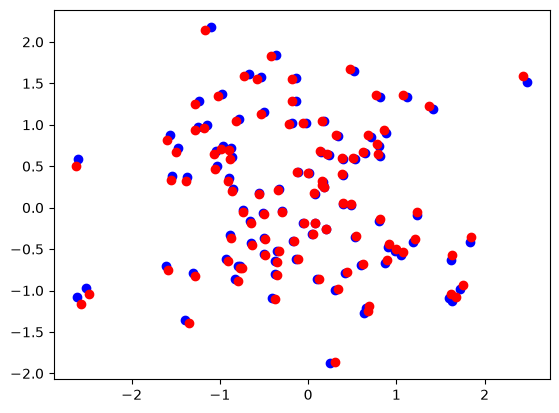

In [100]:
plt.plot(x, y, 'bo')
plt.plot(xr, yr, 'ro')

In [101]:
theta = np.pi / 2
rr_theta = np.array(((cos(theta), -sin(theta)),
                     (sin(theta), cos(theta))))
xr = np.zeros(len(x))
yr = np.zeros(len(y))
for i in range(len(x)):
    xr[i], yr[i] = np.matmul(rr_theta, (x[i], y[i]))

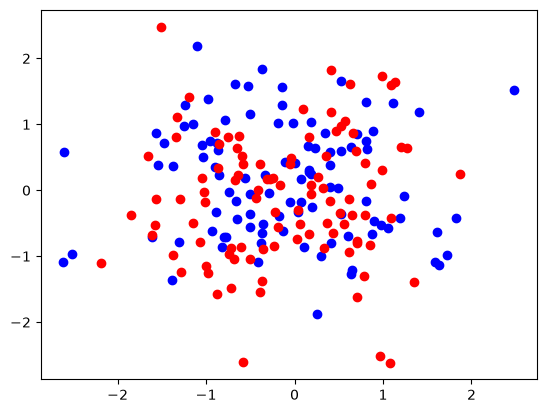

In [102]:
plt.plot(x, y, 'bo')
plt.plot(xr, yr, 'ro')

## Question 10

In [103]:
v1 = np.array((0, 2, 0))
v2 = np.array((3, 0, 0))

In [114]:
def rmat(theta,nhat):
    """Returns 3D rotation matrix thru theta(rad) about unit vector nhat"""
    return linalg.expm(np.cross(np.eye(3),nhat*theta))

In [122]:
# compute rmat for the x axis
rmat_x = rmat(np.pi/2, np.array((1,0,0)))
# print rmat and the rotations
print(f'rotation by pi/2 about x: \n{rmat_x}')
print(f'v1 rotated about x: {np.matmul(rmat_x, v1)}')
print(f'v2 rotated about x: {np.matmul(rmat_x, v2)}')

# compute rmat for the y axis
rmat_y = rmat(np.pi/2, np.array((0,1,0)))
# print rmat and the rotations
print(f'rotation by pi/2 about y: \n{rmat_y}')
print(f'v1 rotated about y: {np.matmul(rmat_y, v1)}')
print(f'v2 rotated about y: {np.matmul(rmat_y, v2)}')

# compute rmat for the z axis
rmat_z = rmat(np.pi/2, np.array((0,0,1)))
# print rmat and the rotations
print(f'rotation by pi/2 about z: \n{rmat_z}')
print(f'v1 rotated about z: {np.matmul(rmat_z, v1)}')
print(f'v2 rotated about z: {np.matmul(rmat_z, v2)}')

rotation by pi/2 about x: 
[[ 1.  0.  0.]
 [ 0.  0. -1.]
 [ 0.  1.  0.]]
v1 rotated about x: [0. 0. 2.]
v2 rotated about x: [3. 0. 0.]
rotation by pi/2 about y: 
[[ 0.  0.  1.]
 [ 0.  1.  0.]
 [-1.  0.  0.]]
v1 rotated about y: [0. 2. 0.]
v2 rotated about y: [ 0.  0. -3.]
rotation by pi/2 about z: 
[[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
v1 rotated about z: [-2.  0.  0.]
v2 rotated about z: [0. 3. 0.]
